In [33]:

import pandas as pd
import numpy as np
import os

In [34]:
df = pd.read_csv(
    'Sample - Superstore.csv',
    encoding='latin1'
)

df['Order Date'] = pd.to_datetime(df['Order Date'])

df['Promotion'] = np.where(
    df['Discount'] > 0,
    1,
    0
)

In [35]:
daily_sales = df.groupby(
    ['Order Date', 'Category']
).agg(
    sales_revenue=('Sales', 'sum'),
    num_transactions=('Quantity', 'sum'),
    promotion_rate=('Promotion', 'mean')
).reset_index()

daily_sales.head()

,Order Date,Category,sales_revenue,num_transactions,promotion_rate
0,2014-01-03,Office Supplies,16.448,2,1.0
1,2014-01-04,Office Supplies,288.060,8,1.0
2,2014-01-05,Office Supplies,19.536,3,1.0
3,2014-01-06,Furniture,2573.820,9,0.0
4,2014-01-06,Office Supplies,685.340,15,0.0


In [36]:
daily_sales['day_of_week'] = (
    daily_sales['Order Date'].dt.day_of_week
)

In [37]:
daily_sales = daily_sales.sort_values(
    by=['Category', 'Order Date']
)

daily_sales['previous_sales'] = (
    daily_sales.groupby('Category')['sales_revenue']
    .shift(1)
)

daily_sales['previous_sales'] = (
    daily_sales['previous_sales'].fillna(0)
)

In [38]:
daily_sales.to_csv(
    'daily_store_sales.csv',
    index=False
)

In [39]:
# Load the saved CSV for our EDA and modeling steps
daily_sales = pd.read_csv('daily_store_sales.csv', parse_dates=['Order Date'])

print(" Loaded 'daily_store_sales.csv' for EDA")
print(f"Dataset shape: {daily_sales.shape}")
daily_sales.head()

 Loaded 'daily_store_sales.csv' for EDA
Dataset shape: (2861, 7)


,Order Date,Category,sales_revenue,num_transactions,promotion_rate,day_of_week,previous_sales
0,2014-01-06,Furniture,2573.820,9,0.0,0,0.000
1,2014-01-07,Furniture,76.728,3,1.0,1,2573.820
2,2014-01-10,Furniture,51.940,1,0.0,4,76.728
3,2014-01-11,Furniture,9.940,2,0.0,5,51.940
4,2014-01-13,Furniture,879.939,9,0.5,0,9.940


In [40]:
daily_sales.isna().sum()

Order Date          0
Category            0
sales_revenue       0
num_transactions    0
promotion_rate      0
day_of_week         0
previous_sales      0
dtype: int64

In [41]:
print("Dataset information:")
daily_sales.info()

print("\nDate range:")
print(daily_sales['Order Date'].min())
print(daily_sales['Order Date'].max())

print("\nNumber of unique categories:")
print(daily_sales['Category'].nunique())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2861 entries, 0 to 2860
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order Date        2861 non-null   datetime64[us]
 1   Category          2861 non-null   str           
 2   sales_revenue     2861 non-null   float64       
 3   num_transactions  2861 non-null   int64         
 4   promotion_rate    2861 non-null   float64       
 5   day_of_week       2861 non-null   int64         
 6   previous_sales    2861 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(2), str(1)
memory usage: 189.3 KB

Date range:
2014-01-03 00:00:00
2017-12-30 00:00:00

Number of unique categories:
3


In [42]:
import plotly.express as px
import plotly.graph_objects as go

day_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

daily_sales['day_name'] = daily_sales['day_of_week'].map(day_names)

daily_sales['day_name'] = pd.Categorical(
    daily_sales['day_name'],
    categories=list(day_names.values()),
    ordered=True
)

print("Plotly imported and day names mapped.")

Plotly imported and day names mapped.


In [43]:
daily_sales['day_name']

0          Monday
1         Tuesday
2          Friday
3        Saturday
4          Monday
          ...    
2856       Monday
2857    Wednesday
2858     Thursday
2859       Friday
2860     Saturday
Name: day_name, Length: 2861, dtype: category
Categories (7, str): ['Monday' < 'Tuesday' < 'Wednesday' < 'Thursday' < 'Friday' < 'Saturday' < 'Sunday']

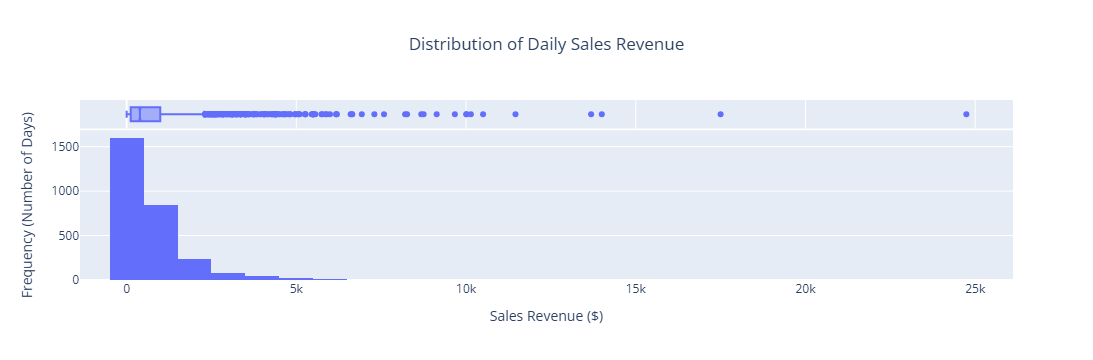

In [44]:
fig = px.histogram(
    daily_sales,
    x='sales_revenue',
    nbins=40,
    marginal='box',
    title='Distribution of Daily Sales Revenue',
    labels={'sales_revenue': 'Sales Revenue ($)'},
    color_discrete_sequence=['#636EFA']
)

fig.update_layout(
    xaxis_title='Sales Revenue ($)',
    yaxis_title='Frequency (Number of Days)',
    title_x=0.5
)

fig.show()

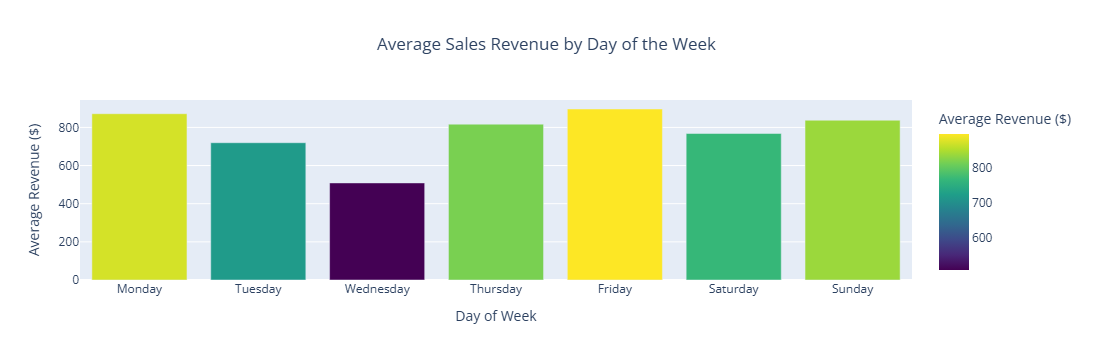

In [45]:
dow_sales = daily_sales.groupby('day_name', observed=False)['sales_revenue'].mean().reset_index()

fig = px.bar(
    dow_sales, 
    x='day_name', 
    y='sales_revenue', 
    title='Average Sales Revenue by Day of the Week',
    labels={'sales_revenue': 'Average Revenue ($)', 'day_name': 'Day of Week'},
    color='sales_revenue', 
    color_continuous_scale='Viridis'
)

fig.update_layout(
    xaxis_title='Day of Week', 
    yaxis_title='Average Revenue ($)',
    title_x=0.5
)
fig.show()

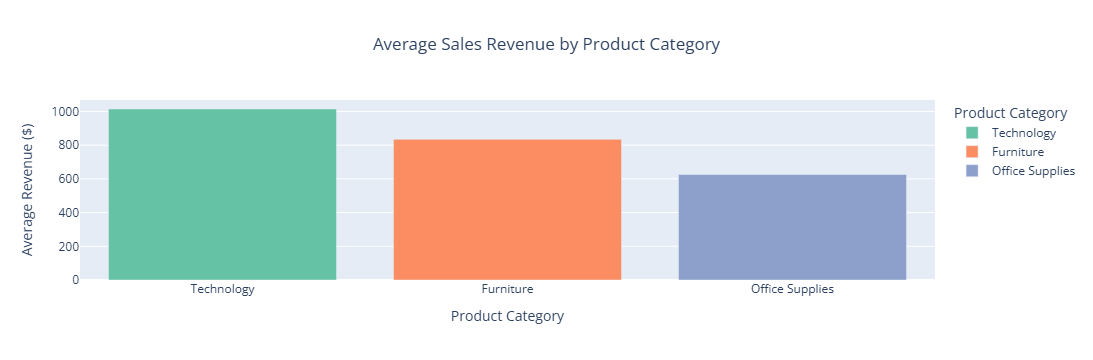

In [46]:
cat_sales = daily_sales.groupby('Category')['sales_revenue'].mean().reset_index().sort_values('sales_revenue', ascending=False)

fig = px.bar(
    cat_sales, 
    x='Category', 
    y='sales_revenue', 
    title='Average Sales Revenue by Product Category',
    labels={'sales_revenue': 'Average Revenue ($)', 'Category': 'Product Category'},
    color='Category', 
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.update_layout(
    xaxis_title='Product Category', 
    yaxis_title='Average Revenue ($)',
    title_x=0.5
)
fig.show()

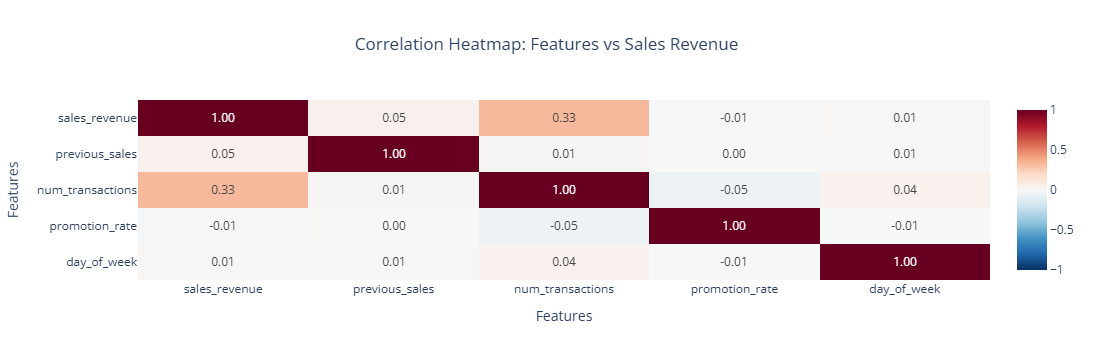


--- Correlation with Sales Revenue (Sorted) ---
num_transactions    0.325916
previous_sales      0.047362
day_of_week         0.009732
promotion_rate     -0.009201
Name: sales_revenue, dtype: float64


In [47]:
numeric_cols = ['sales_revenue', 'previous_sales', 'num_transactions', 'promotion_rate', 'day_of_week']
corr_matrix = daily_sales[numeric_cols].corr()

fig = px.imshow(
    corr_matrix, 
    text_auto='.2f', 
    aspect='auto',
    title='Correlation Heatmap: Features vs Sales Revenue',
    color_continuous_scale='RdBu_r', 
    zmin=-1, 
    zmax=1
)

fig.update_layout(
    xaxis_title='Features', 
    yaxis_title='Features',
    title_x=0.5
)
fig.show()

print("\n--- Correlation with Sales Revenue (Sorted) ---")
print(corr_matrix['sales_revenue'].drop('sales_revenue').sort_values(ascending=False))

In [48]:
# Reload the saved daily data to build our monthly model
daily_sales = pd.read_csv('daily_store_sales.csv', parse_dates=['Order Date'])

# 1. Extract Year and Month
daily_sales['YearMonth'] = daily_sales['Order Date'].dt.to_period('M')

# 2. Aggregate to Monthly level per Category
monthly_sales = daily_sales.groupby(['YearMonth', 'Category']).agg(
    sales_revenue=('sales_revenue', 'sum'),
    num_transactions=('num_transactions', 'sum'),
    promotion_rate=('promotion_rate', 'mean')
).reset_index()

# 3. Sort and create the lag feature
monthly_sales = monthly_sales.sort_values(by=['Category', 'YearMonth'])
monthly_sales['previous_month_sales'] = monthly_sales.groupby('Category')['sales_revenue'].shift(1)
monthly_sales['previous_month_sales'] = monthly_sales['previous_month_sales'].fillna(0)

# 4. Drop the YearMonth period object
monthly_sales = monthly_sales.drop(columns=['YearMonth'])

print(" Data successfully aggregated to a Monthly level!")
print(f"New dataset shape: {monthly_sales.shape}")
monthly_sales.head()

 Data successfully aggregated to a Monthly level!
New dataset shape: (144, 5)


,Category,sales_revenue,num_transactions,promotion_rate,previous_month_sales
0,Furniture,6242.525,70,0.576923,0.000
3,Furniture,1839.658,23,0.400000,6242.525
6,Furniture,14573.956,131,0.838235,1839.658
9,Furniture,7944.837,81,0.458333,14573.956
12,Furniture,6912.787,97,0.843750,7944.837


In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate Features (X) and Target (y)
y_monthly = monthly_sales['sales_revenue']
X_monthly = monthly_sales.drop(columns=['sales_revenue'])

# 2. Encode Categories
X_monthly_encoded = pd.get_dummies(X_monthly, columns=['Category'], drop_first=True, dtype=int)

# 3. Train / Test Split (80/20)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_monthly_encoded, y_monthly, test_size=0.2, random_state=42
)

# 4. Scale the features
scaler_m = StandardScaler()
X_train_m_scaled = scaler_m.fit_transform(X_train_m)
X_test_m_scaled = scaler_m.transform(X_test_m)

# Convert back to DataFrame for feature names later
X_train_m_scaled = pd.DataFrame(X_train_m_scaled, columns=X_train_m.columns, index=X_train_m.index)
X_test_m_scaled = pd.DataFrame(X_test_m_scaled, columns=X_test_m.columns, index=X_test_m.index)

print(" Monthly data preprocessed and scaled!")
print(f"Training on {X_train_m_scaled.shape[0]} months, testing on {X_test_m_scaled.shape[0]} months.")

 Monthly data preprocessed and scaled!
Training on 115 months, testing on 29 months.


In [50]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Initialize the winning model
rf_monthly = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)

# 2. Train the model
rf_monthly.fit(X_train_m_scaled, y_train_m)

# 3. Predict and Evaluate
y_pred_m = rf_monthly.predict(X_test_m_scaled)

mae_m = mean_absolute_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mean_squared_error(y_test_m, y_pred_m))
r2_m = r2_score(y_test_m, y_pred_m)

print(" Monthly Random Forest Performance:")
print("-" * 35)
print(f"MAE  (Mean Absolute Error):  ${mae_m:,.2f}")
print(f"RMSE (Root Mean Sq. Error):  ${rmse_m:,.2f}")
print(f"R²   (R-Squared):            {r2_m:.4f} ({r2_m*100:.1f}%)")

 Monthly Random Forest Performance:
-----------------------------------
MAE  (Mean Absolute Error):  $3,017.12
RMSE (Root Mean Sq. Error):  $3,746.69
R²   (R-Squared):            0.7925 (79.3%)


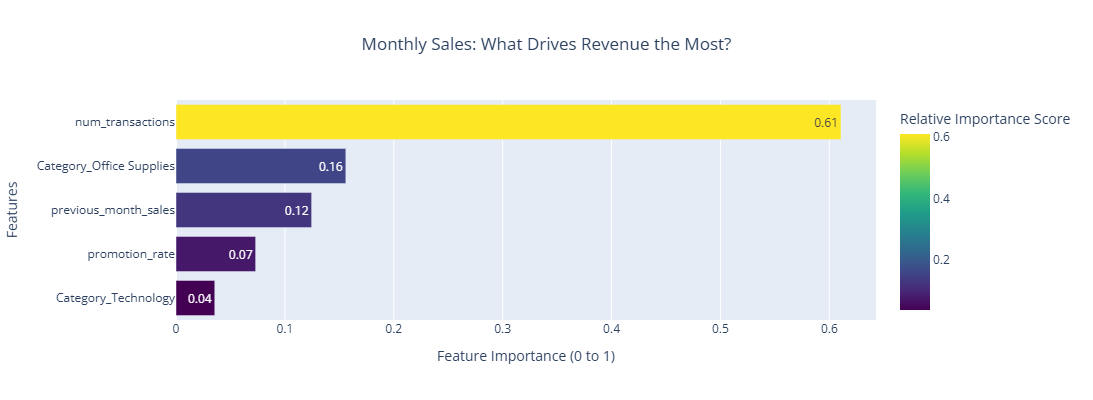

In [51]:
# 1. Extract feature names and importance scores
feature_names = X_train_m_scaled.columns
importances = rf_monthly.feature_importances_

# 2. Create and sort DataFrame
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# 3. Plotly Horizontal Bar Chart
fig = px.bar(
    feature_imp_df, 
    x='Importance', 
    y='Feature', 
    orientation='h',
    title='Monthly Sales: What Drives Revenue the Most?',
    labels={'Importance': 'Relative Importance Score', 'Feature': 'Feature Name'},
    color='Importance',
    color_continuous_scale='Viridis',
    text_auto='.2f'
)

fig.update_layout(
    xaxis_title='Feature Importance (0 to 1)', 
    yaxis_title='Features',
    title_x=0.5,
    showlegend=False,
    height=400
)
fig.show()

In [52]:
import joblib

# Save the scaler and the model to your local directory
joblib.dump(rf_monthly, 'random_forest_monthly_model.pkl')
joblib.dump(scaler_m, 'monthly_scaler.pkl')

print("✅ Model and Scaler saved successfully!")

✅ Model and Scaler saved successfully!
